# CSCI461 - Introduction to Big Data
## Assignment 1: SMS Spam Collection Analysis

### 1. Dataset Loading and Initial Exploration

This project analyzes the SMS Spam Collection dataset to explore
its structure, clean and transform its data, analyze text messages,
and build machine learning models for spam classification.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (5572, 2)
Number of Rows: 5572
Number of Columns: 2


In [5]:
print("Column Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Column Names:
Index(['label', 'message'], dtype='str')

Data Types:
label      str
message    str
dtype: object


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB


In [7]:
df.describe(include="all")

,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [8]:
df.loc[0]

label                                                    ham
message    Go until jurong point, crazy.. Available only ...
Name: 0, dtype: str

In [9]:
df.iloc[0]

label                                                    ham
message    Go until jurong point, crazy.. Available only ...
Name: 0, dtype: str

In [10]:
df.loc[0:4, ["label", "message"]]

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [11]:
df.iloc[0:5, 0:2]

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [12]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
label      0
message    0
dtype: int64

Duplicate Rows:
403


In [13]:
df_clean = df.dropna().drop_duplicates().copy()

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum())

print("\nRemaining Duplicates:")
print(df_clean.duplicated().sum())

Original Shape: (5572, 2)
Cleaned Shape: (5169, 2)

Remaining Missing Values:
label      0
message    0
dtype: int64

Remaining Duplicates:
0


In [14]:
text_columns = ["message"]
categorical_columns = ["label"]
numerical_columns = []

print("Text Columns:", text_columns)
print("Categorical Columns:", categorical_columns)
print("Numerical Columns:", numerical_columns)

Text Columns: ['message']
Categorical Columns: ['label']
Numerical Columns: []


In [15]:
# Transformation 1: Standardize labels
df_clean["label"] = df_clean["label"].str.strip().str.lower()

# Transformation 2: Remove unnecessary spaces from messages
df_clean["message"] = df_clean["message"].str.strip()

# Transformation 3: Calculate message character length
df_clean["message_length"] = df_clean["message"].str.len()

# Transformation 4: Calculate number of words in each message
df_clean["word_count"] = df_clean["message"].str.split().str.len()

print("Transformations completed successfully!")

df_clean.head()

Transformations completed successfully!


,label,message,message_length,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,ham,U dun say so early hor... U c already then say...,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13


In [16]:
print("Updated Dataset Shape:", df_clean.shape)

print("\nUpdated Column Names:")
print(df_clean.columns)

print("\nUpdated Data Types:")
print(df_clean.dtypes)

print("\nUpdated Dataset:")
display(df_clean.head())

Updated Dataset Shape: (5169, 4)

Updated Column Names:
Index(['label', 'message', 'message_length', 'word_count'], dtype='str')

Updated Data Types:
label               str
message             str
message_length    int64
word_count        int64
dtype: object

Updated Dataset:


,label,message,message_length,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,ham,U dun say so early hor... U c already then say...,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13


In [17]:
df_clean.to_csv("../output/cleaned_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [18]:
random_sample = df_clean.sample(n=500, random_state=42)

print("Random Sample:")
display(random_sample.head())

print("\nRandom Sample Shape:")
print(random_sample.shape)

Random Sample:


,label,message,message_length,word_count
1617,ham,"K, makes sense, btw carlos is being difficult ...",121,25
2064,spam,"URGENT! Your mobile No *********** WON a £2,00...",158,26
1272,ham,If you still havent collected the dough pls le...,116,26
3020,ham,Wat time do u wan 2 meet me later?,34,9
3642,spam,"You can stop further club tones by replying ""S...",155,26



Random Sample Shape:
(500, 4)


In [19]:
stratified_sample = (
    df_clean.groupby("label", group_keys=False)
    .sample(frac=0.2, random_state=42)
    .reset_index(drop=True)
)

print("Stratified Sample:")
display(stratified_sample.head())

print("\nOriginal Label Distribution:")
print(df_clean["label"].value_counts(normalize=True))

print("\nStratified Sample Label Distribution:")
print(stratified_sample["label"].value_counts(normalize=True))

Stratified Sample:


,label,message,message_length,word_count
0,ham,"Sorry, I can't help you on this.",32,7
1,ham,How's my loverboy doing ? What does he do that...,144,31
2,ham,Sitting in mu waiting for everyone to get out ...,80,18
3,ham,Sure! I am driving but will reach my destinati...,54,10
4,ham,"Sorry, went to bed early, nightnight",36,6



Original Label Distribution:
label
ham     0.87367
spam    0.12633
Name: proportion, dtype: float64

Stratified Sample Label Distribution:
label
ham     0.873308
spam    0.126692
Name: proportion, dtype: float64


In [20]:
cluster_data = df_clean.copy()

cluster_data["cluster_id"] = np.arange(len(cluster_data)) // 100

selected_clusters = np.random.default_rng(42).choice(
    cluster_data["cluster_id"].unique(),
    size=5,
    replace=False
)

cluster_sample = cluster_data[
    cluster_data["cluster_id"].isin(selected_clusters)
]

print("Selected Clusters:", selected_clusters)

print("\nCluster Sample:")
display(cluster_sample.head())

print("\nCluster Sample Shape:")
print(cluster_sample.shape)

Selected Clusters: [37 22 32  4 51]

Cluster Sample:


,label,message,message_length,word_count,cluster_id
407,ham,All was well until slightly disastrous class t...,168,32,4
408,ham,Hello! Good week? Fancy a drink or something l...,51,9,4
409,ham,Headin towards busetop,22,3,4
410,ham,Message:some text missing* Sender:Name Missing...,152,21,4
411,ham,Come by our room at some point so we can iron ...,75,17,4



Cluster Sample Shape:
(469, 5)


In [21]:
# Count uppercase letters
df_clean["uppercase_count"] = df_clean["message"].apply(
    lambda x: sum(1 for char in x if char.isupper())
)

# Count exclamation marks
df_clean["exclamation_count"] = df_clean["message"].str.count("!")

# Count question marks
df_clean["question_count"] = df_clean["message"].str.count(r"\?")

# Count digits
df_clean["digit_count"] = df_clean["message"].str.count(r"\d")


# Display the new numerical features
numeric_features = [
    "message_length",
    "word_count",
    "uppercase_count",
    "exclamation_count",
    "question_count",
    "digit_count"
]

display(df_clean[numeric_features].head())

print("Numerical Features Summary:")
display(df_clean[numeric_features].describe())

,message_length,word_count,uppercase_count,exclamation_count,question_count,digit_count
0,111,20,3,0,0,0
1,29,6,2,0,0,0
2,155,28,10,0,0,25
3,49,11,2,0,0,0
4,61,13,2,0,0,0


Numerical Features Summary:


,message_length,word_count,uppercase_count,exclamation_count,question_count,digit_count
count,5169.000000,5169.000000,5169.000000,5169.000000,5169.000000,5169.000000
mean,79.306829,15.439930,5.407816,0.243374,0.288450,2.215902
std,58.429357,11.117073,11.778663,0.679167,0.656139,6.031250
min,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,36.000000,7.000000,1.000000,0.000000,0.000000,0.000000
50%,61.000000,12.000000,2.000000,0.000000,0.000000,0.000000
75%,118.000000,22.000000,4.000000,0.000000,0.000000,1.000000
max,910.000000,171.000000,138.000000,11.000000,12.000000,47.000000


In [22]:
# Calculate correlations between numerical features
correlation_matrix = df_clean[numeric_features].corr()

# Display the correlation matrix
display(correlation_matrix)

,message_length,word_count,uppercase_count,exclamation_count,question_count,digit_count
message_length,1.000000,0.973847,0.358961,0.251322,0.095127,0.378764
word_count,0.973847,1.000000,0.322841,0.232689,0.126695,0.283588
uppercase_count,0.358961,0.322841,1.000000,0.275649,0.039758,0.327925
exclamation_count,0.251322,0.232689,0.275649,1.000000,0.033925,0.259593
question_count,0.095127,0.126695,0.039758,0.033925,1.000000,-0.038183
digit_count,0.378764,0.283588,0.327925,0.259593,-0.038183,1.000000


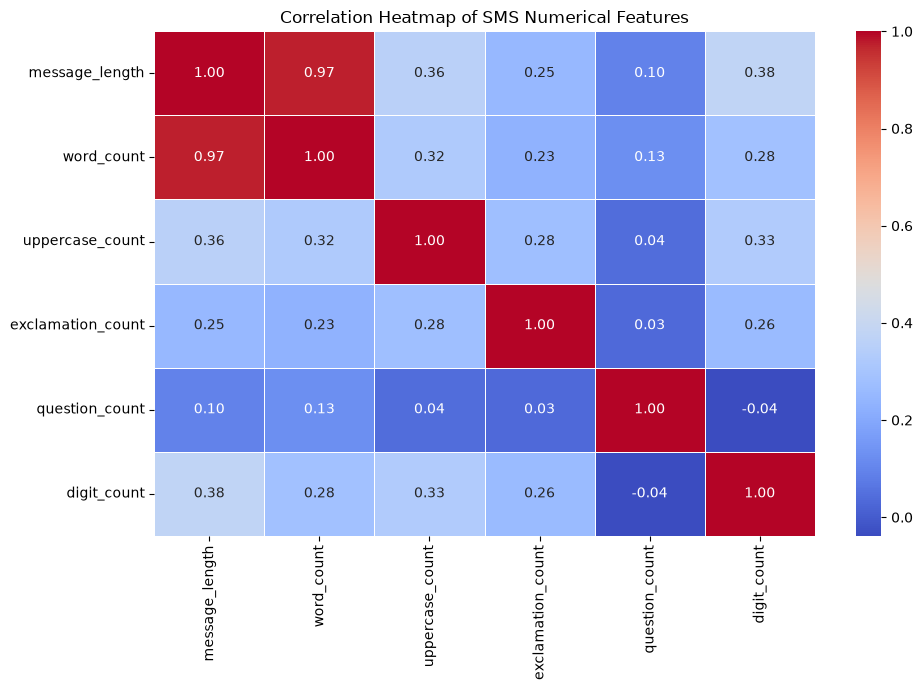

In [23]:
# Create the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of SMS Numerical Features")
plt.tight_layout()

# Save the figure
plt.savefig("../output/figures/correlation_heatmap.png")

plt.show()

In [24]:
# Get the correlation values without comparing a feature with itself
correlation_pairs = correlation_matrix.unstack()

correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0) !=
    correlation_pairs.index.get_level_values(1)
]

# Display the strongest positive and negative correlations
print("Strongest Positive Correlations:")
print(correlation_pairs.sort_values(ascending=False).head(5))

print("\nStrongest Negative Correlations:")
print(correlation_pairs.sort_values().head(5))

Strongest Positive Correlations:
message_length   word_count        0.973847
word_count       message_length    0.973847
message_length   digit_count       0.378764
digit_count      message_length    0.378764
uppercase_count  message_length    0.358961
dtype: float64

Strongest Negative Correlations:
question_count     digit_count         -0.038183
digit_count        question_count      -0.038183
question_count     exclamation_count    0.033925
exclamation_count  question_count       0.033925
uppercase_count    question_count       0.039758
dtype: float64


### Correlation Analysis

A correlation analysis was performed on six numerical features extracted from the SMS messages: message length, word count, uppercase count, exclamation count, question count, and digit count.

The strongest positive correlation was found between message length and word count, with a correlation coefficient of 0.974. This indicates a very strong positive relationship, meaning that longer messages generally contain more words.

Message length also showed moderate positive correlations with digit count (0.379) and uppercase count (0.359). This suggests that longer messages tend to contain more digits and uppercase characters.

On the other hand, question count and digit count showed a very weak negative correlation (-0.038), indicating almost no linear relationship between these features.

Overall, the analysis shows that some numerical text features are strongly related, while others have very weak relationships. These correlations describe associations between features and do not necessarily indicate causation.

In [25]:
# Save the final cleaned dataset with all numerical features
df_clean.to_csv("../output/cleaned_data.csv", index=False)

print("Final cleaned dataset saved successfully!")
print("Final Dataset Shape:", df_clean.shape)
print("Final Dataset Columns:")
print(df_clean.columns.tolist())

Final cleaned dataset saved successfully!
Final Dataset Shape: (5169, 8)
Final Dataset Columns:
['label', 'message', 'message_length', 'word_count', 'uppercase_count', 'exclamation_count', 'question_count', 'digit_count']


In [26]:
import re

# Create a copy of the original messages
df_clean["cleaned_text"] = df_clean["message"].fillna("").copy()

# Convert text to lowercase
df_clean["cleaned_text"] = df_clean["cleaned_text"].str.lower()

# Remove URLs
df_clean["cleaned_text"] = df_clean["cleaned_text"].apply(
    lambda x: re.sub(r"http\S+|www\.\S+", "", x)
)

# Remove punctuation and special characters, but keep letters and numbers
df_clean["cleaned_text"] = df_clean["cleaned_text"].apply(
    lambda x: re.sub(r"[^a-z0-9\s]", " ", x)
)

# Remove extra spaces
df_clean["cleaned_text"] = df_clean["cleaned_text"].apply(
    lambda x: re.sub(r"\s+", " ", x).strip()
)

# Display original and cleaned messages
display(df_clean[["message", "cleaned_text"]].head(10))

,message,cleaned_text
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it s been 3 week s n...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more u r entitled...


In [27]:
# Tokenize each cleaned message
df_clean["tokens"] = df_clean["cleaned_text"].apply(lambda x: x.split())

# Calculate total number of tokens
total_tokens = df_clean["tokens"].apply(len).sum()

# Calculate all unique words
all_words = [
    word
    for message_tokens in df_clean["tokens"]
    for word in message_tokens
]

unique_words = set(all_words)

# Calculate average words per message
average_words = total_tokens / len(df_clean)

# Display results
print("Total Tokens:", total_tokens)
print("Unique Words:", len(unique_words))
print("Average Words per Message:", round(average_words, 2))

Total Tokens: 82392
Unique Words: 8687
Average Words per Message: 15.94


In [28]:
from collections import Counter

# Count how many times each word appears
word_counts = Counter(all_words)

# Get the 20 most frequent words
top_20_words = word_counts.most_common(20)

# Convert results into a DataFrame
top_20_df = pd.DataFrame(
    top_20_words,
    columns=["Word", "Frequency"]
)

# Display the results
display(top_20_df)

,Word,Frequency
0,i,2850
1,you,2148
2,to,2080
3,a,1310
4,the,1245
5,u,1072
6,and,930
7,in,831
8,is,800
9,me,758


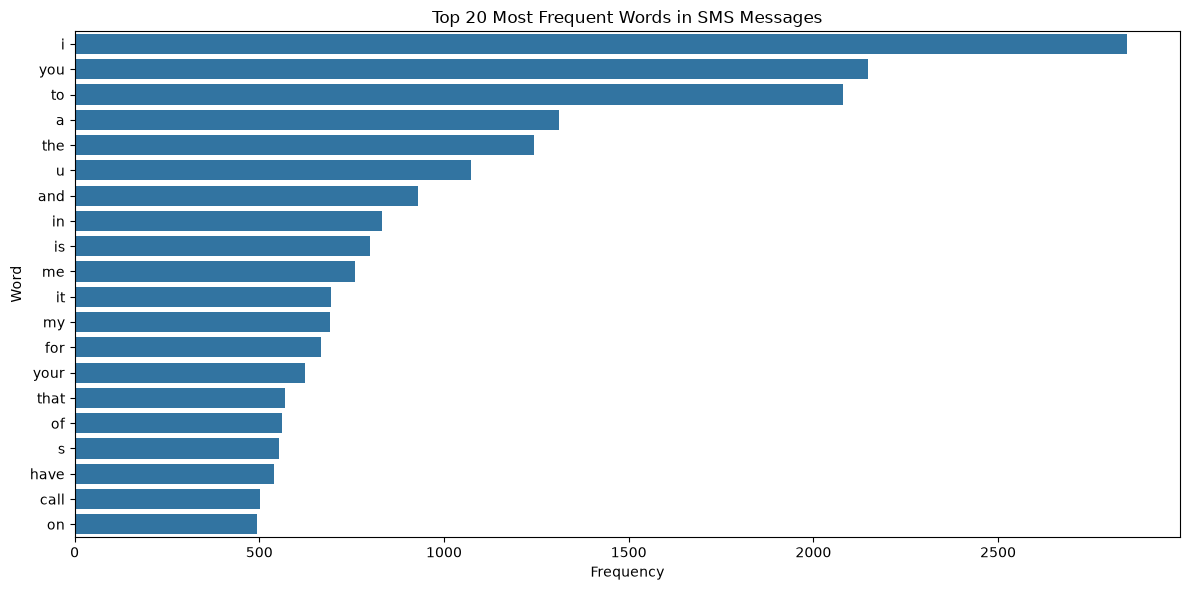

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_20_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequent Words in SMS Messages")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig("../output/figures/top_20_words.png")

plt.show()

In [30]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Convert stop words into a set
stop_words = set(ENGLISH_STOP_WORDS)

print("Number of Stop Words:", len(stop_words))

Number of Stop Words: 318


In [31]:
# Remove stop words from all messages
words_without_stopwords = [
    word
    for word in all_words
    if word not in stop_words
]

# Count the remaining words
word_counts_no_stop = Counter(words_without_stopwords)

# Get the top 20 words
top_20_no_stop = word_counts_no_stop.most_common(20)

# Convert to DataFrame
top_20_no_stop_df = pd.DataFrame(
    top_20_no_stop,
    columns=["Word", "Frequency"]
)

display(top_20_no_stop_df)

,Word,Frequency
0,u,1072
1,s,554
2,2,490
3,t,458
4,m,419
5,just,350
6,ur,322
7,4,288
8,gt,288
9,lt,287


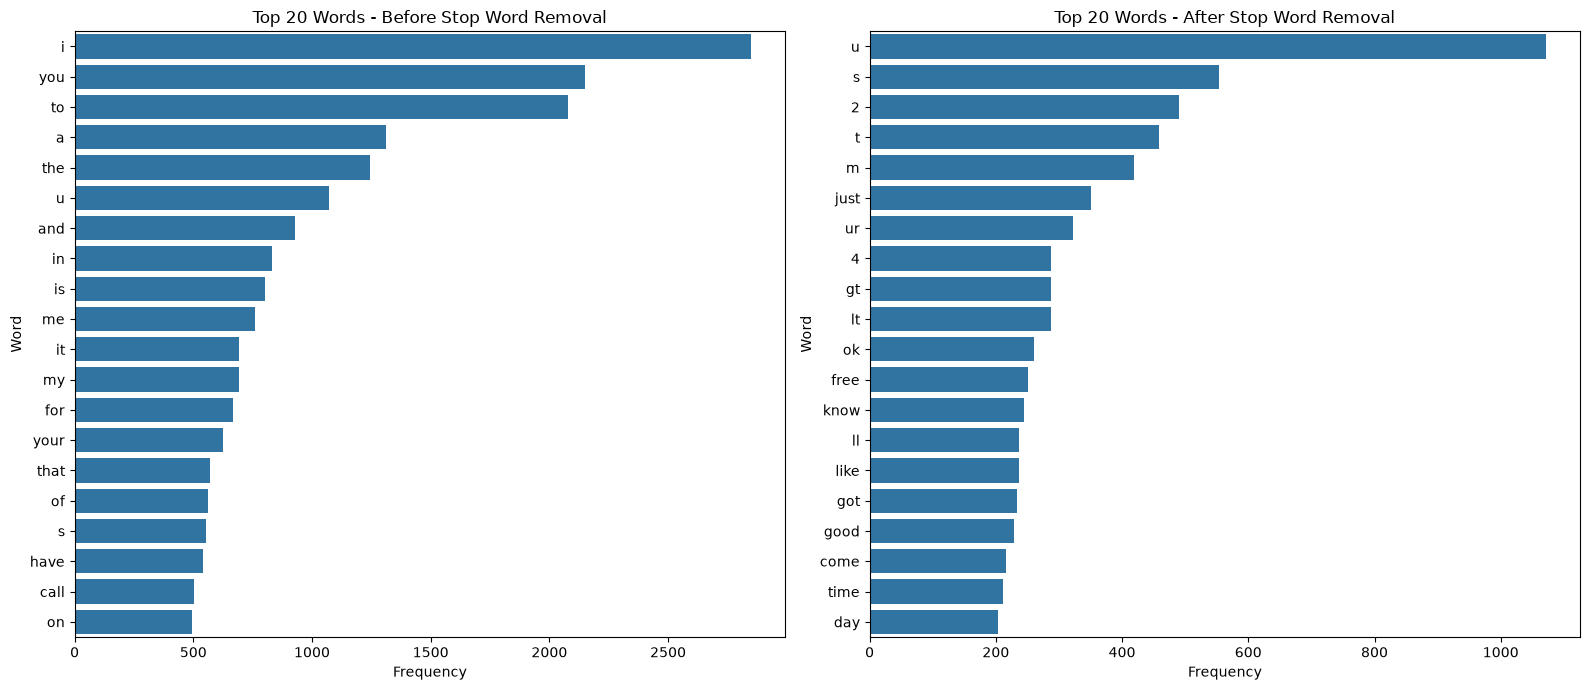

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top words before removing stop words
sns.barplot(
    data=top_20_df,
    x="Frequency",
    y="Word",
    ax=axes[0]
)
axes[0].set_title("Top 20 Words - Before Stop Word Removal")

# Top words after removing stop words
sns.barplot(
    data=top_20_no_stop_df,
    x="Frequency",
    y="Word",
    ax=axes[1]
)
axes[1].set_title("Top 20 Words - After Stop Word Removal")

plt.tight_layout()

plt.savefig("../output/figures/stopwords_comparison.png")

plt.show()

In [33]:
# Group messages by their label
group_comparison = df_clean.groupby("label").agg(
    average_message_length=("message_length", "mean"),
    average_word_count=("word_count", "mean"),
    total_messages=("message", "count")
)

display(group_comparison.round(2))

,average_message_length,average_word_count,total_messages
label,,,
ham,70.87,14.24,4516
spam,137.66,23.74,653


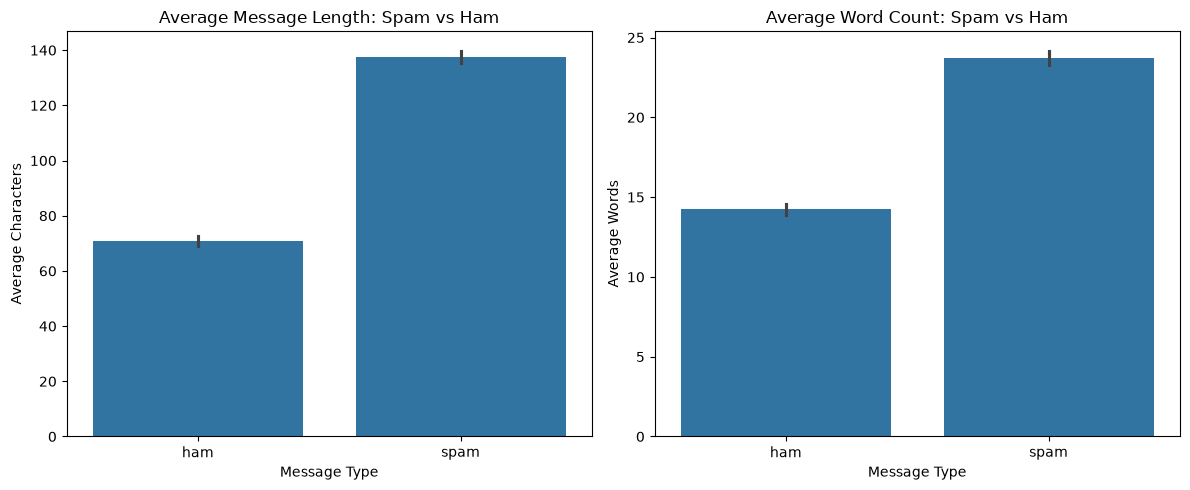

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare average message length
sns.barplot(
    data=df_clean,
    x="label",
    y="message_length",
    estimator="mean",
    ax=axes[0]
)
axes[0].set_title("Average Message Length: Spam vs Ham")
axes[0].set_xlabel("Message Type")
axes[0].set_ylabel("Average Characters")

# Compare average word count
sns.barplot(
    data=df_clean,
    x="label",
    y="word_count",
    estimator="mean",
    ax=axes[1]
)
axes[1].set_title("Average Word Count: Spam vs Ham")
axes[1].set_xlabel("Message Type")
axes[1].set_ylabel("Average Words")

plt.tight_layout()

plt.savefig("../output/figures/spam_ham_comparison.png")

plt.show()

In [35]:
# Separate spam and ham messages
spam_messages = df_clean[df_clean["label"] == "spam"]
ham_messages = df_clean[df_clean["label"] == "ham"]

# Get all words from spam messages
spam_words = [
    word
    for tokens in spam_messages["tokens"]
    for word in tokens
]

# Get all words from ham messages
ham_words = [
    word
    for tokens in ham_messages["tokens"]
    for word in tokens
]

# Count word frequencies
spam_word_counts = Counter(spam_words)
ham_word_counts = Counter(ham_words)

# Get top 10 words from each group
top_10_spam = pd.DataFrame(
    spam_word_counts.most_common(10),
    columns=["Word", "Frequency"]
)

top_10_ham = pd.DataFrame(
    ham_word_counts.most_common(10),
    columns=["Word", "Frequency"]
)

print("Top 10 Words in Spam Messages:")
display(top_10_spam)

print("Top 10 Words in Ham Messages:")
display(top_10_ham)

Top 10 Words in Spam Messages:


,Word,Frequency
0,to,599
1,a,335
2,call,309
3,you,268
4,your,242
5,free,195
6,for,185
7,2,184
8,the,183
9,now,167


Top 10 Words in Ham Messages:


,Word,Frequency
0,i,2793
1,you,1880
2,to,1481
3,the,1062
4,a,975
5,u,930
6,and,826
7,in,762
8,me,732
9,my,679


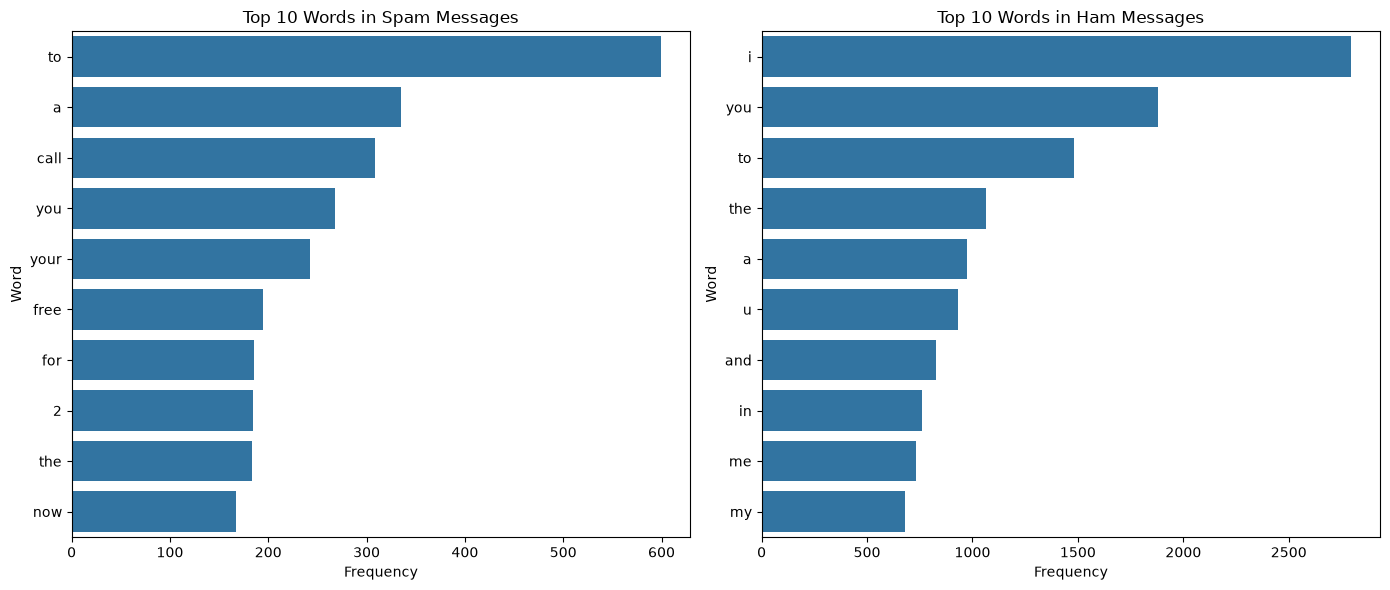

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Spam top 10 words
sns.barplot(
    data=top_10_spam,
    x="Frequency",
    y="Word",
    ax=axes[0]
)
axes[0].set_title("Top 10 Words in Spam Messages")

# Ham top 10 words
sns.barplot(
    data=top_10_ham,
    x="Frequency",
    y="Word",
    ax=axes[1]
)
axes[1].set_title("Top 10 Words in Ham Messages")

plt.tight_layout()

plt.savefig("../output/figures/spam_ham_top_words.png")

plt.show()

## Five Key Insights from Text Analysis

**1. Spam messages are generally longer than ham messages.**

The average spam message contains 137.66 characters, compared to 70.87 characters for ham messages. This indicates that spam messages tend to include more information, promotional content, or instructions.

**2. Spam messages contain more words on average.**

Spam messages contain approximately 23.74 words per message, while ham messages contain 14.24 words. This supports the observation that spam messages are generally longer and more detailed.

**3. Normal messages commonly contain personal and conversational language.**

The most frequent words in ham messages include "i" (2,793 occurrences), "you" (1,880), "me" (732), and "my" (679). This suggests that normal SMS messages often involve personal communication.

**4. Spam messages frequently use promotional and action-oriented language.**

Words such as "call" (309 occurrences), "free" (195), "your" (242), and "now" (167) appear frequently in spam messages. This suggests that spam messages often encourage recipients to take an action or respond to an offer.

**5. The dataset has an imbalanced distribution between spam and ham messages.**

The dataset contains 4,516 ham messages and only 653 spam messages. Therefore, ham messages represent approximately 87.4% of the dataset, while spam messages represent approximately 12.6%. This imbalance should be considered when training and evaluating machine learning models.

In [37]:
# Save the updated cleaned dataset
df_clean.to_csv("../output/cleaned_data.csv", index=False)

print("Updated cleaned dataset saved successfully!")
print("Dataset Shape:", df_clean.shape)

Updated cleaned dataset saved successfully!
Dataset Shape: (5169, 10)


In [38]:
# Input: cleaned SMS messages
X = df_clean["cleaned_text"]

# Output: message labels (spam or ham)
y = df_clean["label"]

print("Input Data Shape:", X.shape)
print("Output Data Shape:", y.shape)

print("\nLabel Distribution:")
print(y.value_counts())

Input Data Shape: (5169,)
Output Data Shape: (5169,)

Label Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [39]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Labels:")
print(y_train.value_counts())

print("\nTesting Labels:")
print(y_test.value_counts())

Training Data: (4135,)
Testing Data: (1034,)

Training Labels:
label
ham     3613
spam     522
Name: count, dtype: int64

Testing Labels:
label
ham     903
spam    131
Name: count, dtype: int64


In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Learn from training messages and convert them into numbers
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert testing messages using the same learned vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display the results
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("\nNumber of words/features:", len(tfidf.get_feature_names_out()))

Training TF-IDF Shape: (4135, 5000)
Testing TF-IDF Shape: (1034, 5000)

Number of words/features: 5000


In [41]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model using training data
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [42]:
# Predict the labels of testing messages
y_pred = model.predict(X_test_tfidf)

# Display some predictions
results = pd.DataFrame({
    "Actual Label": y_test.values,
    "Predicted Label": y_pred,
    "Message": X_test.values
})

print(results.head(10))

  Actual Label Predicted Label  \
0          ham             ham   
1          ham             ham   
2          ham             ham   
3          ham             ham   
4          ham             ham   
5          ham             ham   
6          ham             ham   
7          ham             ham   
8          ham             ham   
9          ham             ham   

                                             Message  
0  good morning my love i go to sleep now and wis...  
1                  and how you will do that princess  
2             cool i ll text you when i m on the way  
3     your right i ll make the appointment right now  
4       aiya we discuss later lar pick up at 4 is it  
5  maybe say hi to and find out if got his card g...  
6  lemme know when i can swing by and pick up i m...  
7  yes please leave at lt gt so that at lt gt we ...  
8                  i am in bus on the way to calicut  
9  o we cant see if we can join denis and mina or...  


In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label="spam")

recall = recall_score(y_test, y_pred, pos_label="spam")

f1 = f1_score(y_test, y_pred, pos_label="spam")

# Display results
print("MODEL EVALUATION RESULTS")
print("-------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

MODEL EVALUATION RESULTS
-------------------------
Accuracy:  0.9603
Precision: 0.9500
Recall:    0.7252
F1-Score:  0.8225


Confusion Matrix:
[[898   5]
 [ 36  95]]


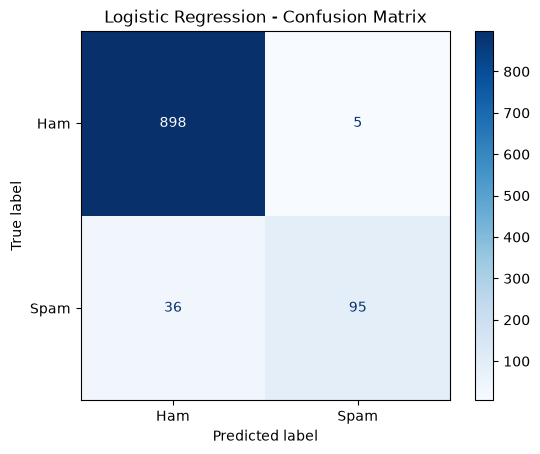

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

# Display the matrix
print("Confusion Matrix:")
print(cm)

# Create visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.savefig("../output/figures/confusion_matrix.png", bbox_inches="tight")
plt.show()

In [45]:
with open("../output/model_metrics.txt", "w") as file:

    file.write("LOGISTIC REGRESSION MODEL EVALUATION\n")
    file.write("====================================\n\n")

    file.write(f"Accuracy:  {accuracy:.4f}\n")
    file.write(f"Precision: {precision:.4f}\n")
    file.write(f"Recall:    {recall:.4f}\n")
    file.write(f"F1-Score:  {f1:.4f}\n\n")

    file.write("CONFUSION MATRIX\n")
    file.write("----------------\n")
    file.write(f"True Negatives (Ham correctly identified): {cm[0][0]}\n")
    file.write(f"False Positives (Ham classified as Spam): {cm[0][1]}\n")
    file.write(f"False Negatives (Spam classified as Ham): {cm[1][0]}\n")
    file.write(f"True Positives (Spam correctly identified): {cm[1][1]}\n\n")

    file.write("INTERPRETATION\n")
    file.write("--------------\n")
    file.write("The model achieved 96.03% accuracy.\n")
    file.write("It achieved high precision, meaning most messages predicted as spam were actually spam.\n")
    file.write("Recall was lower, meaning some actual spam messages were missed.\n")
    file.write("The model correctly identified 95 spam messages but missed 36.\n")

print("Model metrics saved successfully!")

Model metrics saved successfully!


In [46]:
# Convert all messages into TF-IDF numerical features
all_messages_tfidf = tfidf.transform(df_clean["cleaned_text"])

print("Clustering Data Shape:", all_messages_tfidf.shape)

Clustering Data Shape: (5169, 5000)


In [47]:
from sklearn.cluster import KMeans

# Create the K-Means model
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Group messages into two clusters
clusters = kmeans.fit_predict(all_messages_tfidf)

# Add cluster assignments to our dataset
df_clean["cluster"] = clusters

# Display the number of messages in each cluster
print("CLUSTER SIZES")
print("-------------")
print(df_clean["cluster"].value_counts().sort_index())

CLUSTER SIZES
-------------
cluster
0    1325
1    3844
Name: count, dtype: int64


In [48]:
# Compare K-Means clusters with actual labels
cluster_comparison = pd.crosstab(
    df_clean["cluster"],
    df_clean["label"]
)

print("CLUSTER VS ACTUAL LABELS")
print("------------------------")
print(cluster_comparison)

CLUSTER VS ACTUAL LABELS
------------------------
label     ham  spam
cluster            
0        1209   116
1        3307   537


In [49]:
from sklearn.metrics import silhouette_score

# Calculate silhouette score
sil_score = silhouette_score(
    all_messages_tfidf,
    clusters,
    sample_size=1000,
    random_state=42
)

print("Silhouette Score:", round(sil_score, 4))

Silhouette Score: 0.004


In [50]:
# Get all words learned by TF-IDF
terms = tfidf.get_feature_names_out()

# Get the most important words in each cluster
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

print("TOP WORDS IN EACH CLUSTER")
print("=========================")

for i in range(2):
    print(f"\nCluster {i}:")

    top_words = [terms[index] for index in order_centroids[i, :15]]

    print(", ".join(top_words))

TOP WORDS IN EACH CLUSTER

Cluster 0:
you, to, are, and, me, the, have, do, in, that, how, when, your, can, what

Cluster 1:
to, the, is, in, it, me, my, for, and, ok, now, your, on, of, that


In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create improved TF-IDF vectorizer
tfidf_improved = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

# Convert all messages into numerical features
X_improved = tfidf_improved.fit_transform(df_clean["cleaned_text"])

print("Original TF-IDF Shape:", all_messages_tfidf.shape)
print("Improved TF-IDF Shape:", X_improved.shape)
print("Number of features:", len(tfidf_improved.get_feature_names_out()))

Original TF-IDF Shape: (5169, 5000)
Improved TF-IDF Shape: (5169, 5000)
Number of features: 5000


In [54]:
from sklearn.decomposition import TruncatedSVD

# Create the dimensionality reduction model
svd = TruncatedSVD(n_components=100, random_state=42)

# Reduce the TF-IDF features
X_reduced = svd.fit_transform(X_improved)

# Display results
print("Original Features:", X_improved.shape)
print("Reduced Features:", X_reduced.shape)

print("\nTotal Explained Variance:",
      round(svd.explained_variance_ratio_.sum(), 4))

Original Features: (5169, 5000)
Reduced Features: (5169, 100)

Total Explained Variance: 0.2599


In [55]:
# Create improved K-Means model
kmeans_improved = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Perform clustering on reduced data
clusters_improved = kmeans_improved.fit_predict(X_reduced)

# Display cluster sizes
print("IMPROVED CLUSTER SIZES")
print("----------------------")

print(pd.Series(clusters_improved).value_counts().sort_index())

IMPROVED CLUSTER SIZES
----------------------
0    4956
1     213
Name: count, dtype: int64


In [56]:
# Calculate improved silhouette score
sil_score_improved = silhouette_score(
    X_reduced,
    clusters_improved,
    sample_size=1000,
    random_state=42
)

print("Original Silhouette Score:", round(sil_score, 4))
print("Improved Silhouette Score:", round(sil_score_improved, 4))

Original Silhouette Score: 0.004
Improved Silhouette Score: 0.1432


In [57]:
# Store improved cluster assignments
df_clean["improved_cluster"] = clusters_improved

# Compare improved clusters with actual labels
improved_comparison = pd.crosstab(
    df_clean["improved_cluster"],
    df_clean["label"]
)

print("IMPROVED CLUSTER VS ACTUAL LABELS")
print("---------------------------------")
print(improved_comparison)

IMPROVED CLUSTER VS ACTUAL LABELS
---------------------------------
label              ham  spam
improved_cluster            
0                 4305   651
1                  211     2


In [58]:
# Test different numbers of SVD components
for n in [50, 200]:

    svd_test = TruncatedSVD(
        n_components=n,
        random_state=42
    )

    X_test_reduced = svd_test.fit_transform(X_improved)

    kmeans_test = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )

    clusters_test = kmeans_test.fit_predict(X_test_reduced)

    score = silhouette_score(
        X_test_reduced,
        clusters_test,
        sample_size=1000,
        random_state=42
    )

    print(f"\nComponents: {n}")
    print("Explained Variance:",
          round(svd_test.explained_variance_ratio_.sum(), 4))
    print("Silhouette Score:", round(score, 4))
    print("Cluster Sizes:")
    print(pd.Series(clusters_test).value_counts().sort_index())


Components: 50
Explained Variance: 0.168
Silhouette Score: 0.2349
Cluster Sizes:
0    4969
1     200
Name: count, dtype: int64

Components: 200
Explained Variance: 0.382
Silhouette Score: 0.069
Cluster Sizes:
0    4968
1     201
Name: count, dtype: int64


In [59]:
# Create the final candidate with 50 components
svd_final = TruncatedSVD(
    n_components=50,
    random_state=42
)

X_final_reduced = svd_final.fit_transform(X_improved)

# Train K-Means
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters_final = kmeans_final.fit_predict(X_final_reduced)

# Save cluster assignments
df_clean["final_cluster"] = clusters_final

# Compare clusters with actual labels
final_comparison = pd.crosstab(
    df_clean["final_cluster"],
    df_clean["label"]
)

print("FINAL CANDIDATE CLUSTER COMPARISON")
print("----------------------------------")
print(final_comparison)

FINAL CANDIDATE CLUSTER COMPARISON
----------------------------------
label           ham  spam
final_cluster            
0              4316   653
1               200     0


In [61]:
with open("../output/cluster_summary.txt", "w") as file:

    file.write("K-MEANS CLUSTERING REPORT\n")
    file.write("========================\n\n")

    file.write("FINAL MODEL CONFIGURATION\n")
    file.write("-------------------------\n")
    file.write("Algorithm: K-Means\n")
    file.write("Number of clusters: 2\n")
    file.write("TF-IDF maximum features: 5000\n")
    file.write("Stop words: English\n")
    file.write("Dimensionality reduction: TruncatedSVD\n")
    file.write("SVD components: 50\n")
    file.write(f"Explained variance: {svd_final.explained_variance_ratio_.sum():.4f}\n")
    file.write(f"Silhouette score: {sil_score_final:.4f}\n\n")

    file.write("CLUSTER SIZES\n")
    file.write("-------------\n")
    file.write(df_clean["cluster"].value_counts().sort_index().to_string())
    file.write("\n\n")

    file.write("CLUSTER VS ACTUAL LABELS\n")
    file.write("-----------------------\n")
    file.write(final_comparison.to_string())
    file.write("\n\n")

    file.write("EXPERIMENT COMPARISON\n")
    file.write("--------------------\n")
    file.write("Original TF-IDF: 0.0040\n")
    file.write("SVD 100 components: 0.1432\n")
    file.write("SVD 50 components: 0.2349\n")
    file.write("SVD 200 components: 0.0690\n\n")

    file.write("INTERPRETATION\n")
    file.write("--------------\n")
    file.write(
        "The 50-component model achieved the highest silhouette score "
        "among the tested configurations.\n"
    )
    file.write(
        "However, Cluster 0 contained 4316 ham and 653 spam messages, "
        "while Cluster 1 contained 200 ham and zero spam messages.\n"
    )
    file.write(
        "Therefore, the improved clustering achieved better geometric "
        "separation but did not successfully separate spam from ham.\n"
    )

print("Final cluster summary saved successfully!")

Final cluster summary saved successfully!


In [62]:
# Save final cluster assignments
df_clean["cluster"] = df_clean["final_cluster"]

# Save the updated cleaned dataset
df_clean.to_csv("../output/cleaned_data.csv", index=False)

# Calculate final silhouette score
sil_score_final = silhouette_score(
    X_final_reduced,
    clusters_final,
    sample_size=1000,
    random_state=42
)

print("FINAL CLUSTERING RESULTS")
print("-----------------------")
print("Number of clusters:", 2)
print("SVD Components:", 50)
print("Explained Variance:",
      round(svd_final.explained_variance_ratio_.sum(), 4))
print("Silhouette Score:", round(sil_score_final, 4))

print("\nCluster Sizes:")
print(df_clean["cluster"].value_counts().sort_index())

print("\nFinal cleaned dataset saved!")

FINAL CLUSTERING RESULTS
-----------------------
Number of clusters: 2
SVD Components: 50
Explained Variance: 0.168
Silhouette Score: 0.2349

Cluster Sizes:
cluster
0    4969
1     200
Name: count, dtype: int64

Final cleaned dataset saved!
